In [2]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Artificial intelligence is changing the world of technology.
It helps computers learn from data and solve problems.
AI is used in healthcare, education, and business.
I enjoy learning about AI because it makes work easier.
In the future, technology will become even more useful."""

clean_text = re.sub(r'[^\w\s]', '', text.lower())

print("Clean text:")
print(clean_text)

words = word_tokenize(text.lower())
sentences = sent_tokenize(text)

print("\nWord tokens:")
print(words)

print("\nSentences:")
print(sentences)

print("\nUsing split():")
print(text.split())

print("\nUsing word_tokenize():")
print(word_tokenize(text))

stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in word_tokenize(clean_text)
    if word not in stop_words
]

print("\nWords without stopwords:")
print(filtered_words)

frequency = Counter(filtered_words)

print("\nWord frequency:")
print(frequency.most_common())

[nltk_data] Downloading package punkt to C:\Users\Jai
[nltk_data]     Karan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Jai
[nltk_data]     Karan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Jai
[nltk_data]     Karan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Clean text:
artificial intelligence is changing the world of technology
it helps computers learn from data and solve problems
ai is used in healthcare education and business
i enjoy learning about ai because it makes work easier
in the future technology will become even more useful

Word tokens:
['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'of', 'technology', '.', 'it', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'problems', '.', 'ai', 'is', 'used', 'in', 'healthcare', ',', 'education', ',', 'and', 'business', '.', 'i', 'enjoy', 'learning', 'about', 'ai', 'because', 'it', 'makes', 'work', 'easier', '.', 'in', 'the', 'future', ',', 'technology', 'will', 'become', 'even', 'more', 'useful', '.']

Sentences:
['Artificial intelligence is changing the world of technology.', 'It helps computers learn from data and solve problems.', 'AI is used in healthcare, education, and business.', 'I enjoy learning about AI because it makes work easier.', 'In the fut

In [3]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('wordnet')
nltk.download('omw-1.4')

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

filtered_words = [
    word for word in words
    if word not in stop_words
]

ps = PorterStemmer()
stemmed_words = [ps.stem(word) for word in filtered_words]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]

print("Original words:")
print(filtered_words)

print("\nStemmed words:")
print(stemmed_words)

print("\nLemmatized words:")
print(lemmatized_words)

print("\nComparison:")
for i in range(len(filtered_words)):
    print(filtered_words[i], "->", stemmed_words[i],
          "|", lemmatized_words[i])

[nltk_data] Downloading package wordnet to C:\Users\Jai
[nltk_data]     Karan\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to C:\Users\Jai
[nltk_data]     Karan\AppData\Roaming\nltk_data...


Original words:
['artificial', 'intelligence', 'changing', 'world', 'technology', 'helps', 'computers', 'learn', 'data', 'solve', 'problems', 'ai', 'used', 'healthcare', 'education', 'business', 'enjoy', 'learning', 'ai', 'makes', 'work', 'easier', 'future', 'technology', 'become', 'even', 'useful']

Stemmed words:
['artifici', 'intellig', 'chang', 'world', 'technolog', 'help', 'comput', 'learn', 'data', 'solv', 'problem', 'ai', 'use', 'healthcar', 'educ', 'busi', 'enjoy', 'learn', 'ai', 'make', 'work', 'easier', 'futur', 'technolog', 'becom', 'even', 'use']

Lemmatized words:
['artificial', 'intelligence', 'changing', 'world', 'technology', 'help', 'computer', 'learn', 'data', 'solve', 'problem', 'ai', 'used', 'healthcare', 'education', 'business', 'enjoy', 'learning', 'ai', 'make', 'work', 'easier', 'future', 'technology', 'become', 'even', 'useful']

Comparison:
artificial -> artifici | artificial
intelligence -> intellig | intelligence
changing -> chang | changing
world -> world | 

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps computers learn and solve problems.",
    "Blockchain stores information securely across a distributed network.",
    "Cloud computing provides online storage and computing services."
]

cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("Bag of Words:")
print(cv.get_feature_names_out())
print(bow.toarray())

tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform(texts)

features = tfidf.get_feature_names_out()

print("\nTop 3 keywords in each text:")

for i in range(len(texts)):
    scores = matrix[i].toarray()[0]
    top_indices = scores.argsort()[::-1][:3]

    print("\nText", i + 1)
    for index in top_indices:
        print(features[index], ":", round(scores[index], 3))

Bag of Words:
['across' 'and' 'artificial' 'blockchain' 'cloud' 'computers' 'computing'
 'distributed' 'helps' 'information' 'intelligence' 'learn' 'network'
 'online' 'problems' 'provides' 'securely' 'services' 'solve' 'storage'
 'stores']
[[0 1 1 0 0 1 0 0 1 0 1 1 0 0 1 0 0 0 1 0 0]
 [1 0 0 1 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0 0 1]
 [0 1 0 0 1 0 2 0 0 0 0 0 0 1 0 1 0 1 0 1 0]]

Top 3 keywords in each text:

Text 1
intelligence : 0.363
helps : 0.363
solve : 0.363

Text 2
stores : 0.378
network : 0.378
blockchain : 0.378

Text 3
computing : 0.646
services : 0.323
provides : 0.323


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """
Artificial intelligence allows computers to learn from data.
It helps automate tasks and solve complex problems.
AI is used in healthcare, education, and business.
It can improve efficiency and decision making.
"""

text2 = """
Blockchain stores digital information in linked blocks.
It provides transparency and security for transactions.
Blockchain is used in finance and digital records.
It can improve trust between different users.
"""

words1 = set(re.findall(r'\b[a-zA-Z]+\b', text1.lower()))
words2 = set(re.findall(r'\b[a-zA-Z]+\b', text2.lower()))

jaccard = len(words1 & words2) / len(words1 | words2)

print("Jaccard similarity:", round(jaccard, 3))

vectorizer = TfidfVectorizer()
vectors = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(vectors[0], vectors[1])[0][0]

print("Cosine similarity:", round(cosine, 3))

Jaccard similarity: 0.156
Cosine similarity: 0.265


In [7]:
!pip install textblob wordcloud

   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------- ----------------------- 262.1/625.0 kB ? eta -:--:--
   ---------------------------------------- 625.0/625.0 kB 2.0 MB/s  0:00:00

   ---------------------------------------- 0/2 [wordcloud]
   ---------------------------------------- 0/2 [wordcloud]
   -------------------- ------------------- 1/2 [textblob]
   -------------------- ------------------- 1/2 [textblob]
   -------------------- ------------------- 1/2 [textblob]
   -------------------- ------------------- 1/2 [textblob]
   -------------------- ------------------- 1/2 [textblob]
   ---------------------------------------- 2/2 [textblob]



[nltk_data] Downloading package punkt to C:\Users\Jai
[nltk_data]     Karan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package brown to C:\Users\Jai
[nltk_data]     Karan\AppData\Roaming\nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package movie_reviews to C:\Users\Jai
[nltk_data]     Karan\AppData\Roaming\nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!



Review: This laptop is excellent and works very smoothly.
Polarity: 0.76
Subjectivity: 0.825
Sentiment: Positive

Review: The product is terrible and the battery is disappointing.
Polarity: -0.8
Subjectivity: 0.85
Sentiment: Negative

Review: The laptop is average and has a normal design.
Polarity: 0.0
Subjectivity: 0.525
Sentiment: Neutral


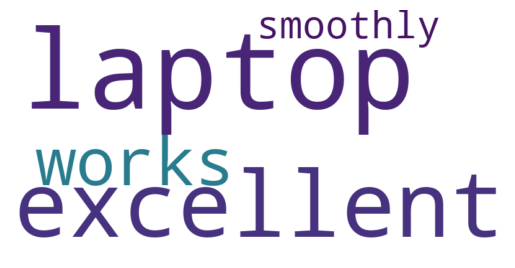

In [8]:
import nltk
nltk.download('punkt')
nltk.download('brown')
nltk.download('movie_reviews')

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "This laptop is excellent and works very smoothly.",
    "The product is terrible and the battery is disappointing.",
    "The laptop is average and has a normal design."
]

positive_reviews = []

for review in reviews:
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)

# Word cloud for positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    cloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.show()

In [3]:
import numpy as np
import random as random
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """
Technology helps people communicate and learn.
Computers solve problems and process information.
Artificial intelligence helps machines learn from data.
Students use technology for education and research.
The internet provides information to people around the world.
Technology improves healthcare, education, and business.
Learning new skills helps people adapt to change.
People should use technology responsibly.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

sequence = tokenizer.texts_to_sequences([text])[0]
vocab_size = len(tokenizer.word_index) + 1

X = []
y = []

for i in range(1, len(sequence)):
    X.append(sequence[:i])
    y.append(sequence[i])

X = pad_sequences(X, padding="pre")
y = np.array(y)

model = Sequential([
    Embedding(vocab_size, 16),
    LSTM(32),
    Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy"
)

with tf.device("/CPU:0"):
    model.fit(X, y, epochs=20, verbose=1)

def generate_text(seed, count=10):
    result = seed.lower()

    for i in range(count):
        seq = tokenizer.texts_to_sequences([result])[0]
        seq = pad_sequences([seq], maxlen=X.shape[1], padding="pre")

        prediction = model.predict(seq, verbose=0)[0]

        top_words = prediction.argsort()[-10:]

        next_word_id = random.choice(top_words)

        next_word = tokenizer.index_word.get(next_word_id, "")

        if next_word == "":
            break

        result += " " + next_word

    return result

print(generate_text("technology", 10))
print(generate_text("computers", 10))
print(generate_text("students", 10))

Epoch 1/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - loss: 3.6385
Epoch 2/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 3.6358
Epoch 3/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - loss: 3.6337 
Epoch 4/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - loss: 3.6318
Epoch 5/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - loss: 3.6297
Epoch 6/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - loss: 3.6274
Epoch 7/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - loss: 3.6253 
Epoch 8/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - loss: 3.6226
Epoch 9/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - loss: 3.6204 
Epoch 10/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 3.6173
Epoch 11/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - loss: 3.6144
Epoch 12/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 3.6105 
Epoch 13/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - loss: 3.6070
Epoch 14/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 3.6026 
Epoch 15/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - loss: 3.5968
Epoch 16/20
2/2 ━━━━━━━